<a href="https://colab.research.google.com/github/nurilhuda05/Pembelajaran_Mesin_2026/blob/main/TG14_244107020004_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PRAKTIKUM 1**

### **Langkah 1 - Import Library dan Menghubungkan Google Drive**

In [17]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Langkah 2 - Pra Pengolahan Data**

#### **2.1. Pra Pengolahan Data Training**

In [18]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)

training_set = train_datagen.flow_from_directory('/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/dataset/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')

Found 8011 images belonging to 2 classes.


#### **2.2. Pra Pengolahan Data Testing**

In [19]:
test_datagen = ImageDataGenerator(rescale = 1./255)

test_set = test_datagen.flow_from_directory('/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 2000 images belonging to 2 classes.


### **Langkah 3 - Pembuatan Model CNN**

#### **3.1.  - Inisiasi Model CNN**

In [20]:
cnn = tf.keras.models.Sequential()

#### **3.2. - Pembuatan Layer Konvolusi 1**

In [21]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

#### **3.3 - Pembuatan Layer Pooling 1**

In [22]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

#### **3.4 - Pembuatan Layer Konvolusi 2 dan Pooling 2**

In [23]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

#### **3.5 - Flattening**

In [24]:
cnn.add(tf.keras.layers.Flatten())

#### **3.6 - Fully Connected Layer 1 (Input)**

In [25]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

#### **3.7 - Fully Connected Layer 2 (Output)**

In [26]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

#### **3.8 - Compile Model CNN**

In [27]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

### **Langkah 4 - Fit CNN**

In [28]:
cnn.fit(x = training_set, validation_data = test_set, epochs = 25)

Epoch 1/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 625s 2s/step - accuracy: 0.6044 - loss: 0.6582 - val_accuracy: 0.6795 - val_loss: 0.5986
Epoch 2/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 109s 433ms/step - accuracy: 0.6988 - loss: 0.5795 - val_accuracy: 0.7480 - val_loss: 0.5369
Epoch 3/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 97s 387ms/step - accuracy: 0.7270 - loss: 0.5387 - val_accuracy: 0.7215 - val_loss: 0.5580
Epoch 4/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 95s 377ms/step - accuracy: 0.7527 - loss: 0.5088 - val_accuracy: 0.7455 - val_loss: 0.5289
Epoch 5/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 96s 385ms/step - accuracy: 0.7630 - loss: 0.4977 - val_accuracy: 0.7595 - val_loss: 0.5055
Epoch 6/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 97s 385ms/step - accuracy: 0.7681 - loss: 0.4811 - val_accuracy: 0.7365 - val_loss: 0.5366
Epoch 7/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 105s 420ms/step - accuracy: 0.7771 - loss: 0.4653 - val_accuracy: 0.7620 - val_loss: 0.5096
Epoch 8/25
251/251 ━━━━━━━━━━━━━━━━━━━━ 96s 381ms/step - accuracy: 0.7889 - loss: 0

### **Langkah 5 - Prediksi dengan 1 Citra**

In [29]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Memuat gambar dari Google Drive
test_image = image.load_img('/content/drive/MyDrive/Semester 5/Pembelajaran Mesin/Data/dataset/single_prediction/cat_or_dog_1.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)

# Melakukan prediksi
result = cnn.predict(test_image)
training_set.class_indices

# Menentukan hasil klasifikasi
if result[0][0] == 1:
  prediction = 'dog'
else:
  prediction = 'cat'

print("Hasil prediksi:", prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Hasil prediksi: dog


# **PRAKTIKUM 2**

### **Langkah 1 - Load Library**

In [30]:
import tensorflow as tf

from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

### **Langkah 2 - Unduh Dataset CIFAR**

In [31]:
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2916s 17us/step


### **Langkah 3 - Verifikasi Data**

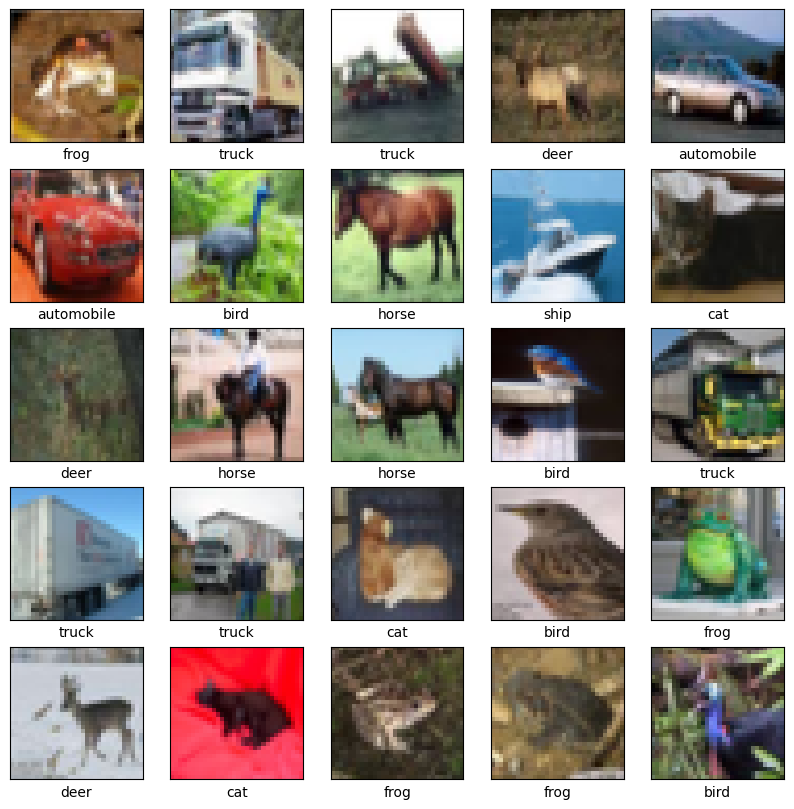

In [32]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

### **Langkah 4 - Buat Model CNN**

#### **4.1. - Buat Layer Konvolusi**

In [33]:
model = models.Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(64, (3, 3), activation='relu'))

#### **4.2. - Cek Arsitektur Konvolusi**

In [34]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

#### **4.3. - Tambahkan Layer Fully Connected**

In [35]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

#### **4.4. - Cek Arsitektur Model CNN**

In [36]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

#### **4.5. - Compile Model CNN**

In [37]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

### **Langkah 5 - Fit Model**

In [38]:
history = model.fit(train_images, train_labels, epochs=10, validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 135s 85ms/step - accuracy: 0.4310 - loss: 1.5594 - val_accuracy: 0.5326 - val_loss: 1.2957
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 119s 76ms/step - accuracy: 0.5759 - loss: 1.1937 - val_accuracy: 0.6051 - val_loss: 1.1068
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 148s 80ms/step - accuracy: 0.6360 - loss: 1.0389 - val_accuracy: 0.6298 - val_loss: 1.0380
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 121s 78ms/step - accuracy: 0.6692 - loss: 0.9434 - val_accuracy: 0.6560 - val_loss: 0.9857
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 132s 85ms/step - accuracy: 0.6995 - loss: 0.8599 - val_accuracy: 0.6686 - val_loss: 0.9552
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 124s 79ms/step - accuracy: 0.7184 - loss: 0.8086 - val_accuracy: 0.6883 - val_loss: 0.9059
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 134s 75ms/step - accuracy: 0.7364 - loss: 0.7570 - val_accuracy: 0.7080 - val_loss: 0.8551
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 113s 72ms/step - accuracy: 

### **Langkah 6 - Evaluasi Model**

313/313 - 7s - 23ms/step - accuracy: 0.6987 - loss: 0.8978


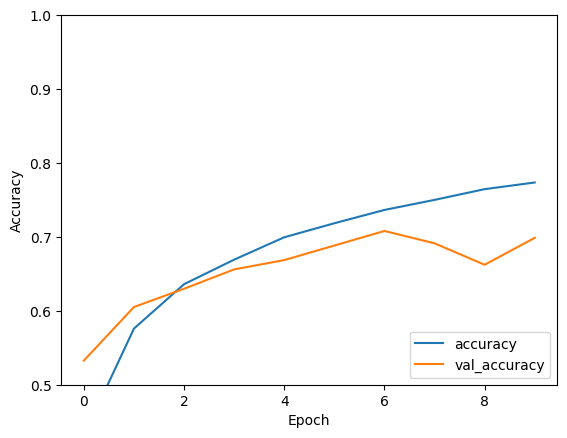

In [39]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')

test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

### **Langkah 7 - Cetak Hasil Akurasi**

In [40]:
print(test_acc)

0.6987000107765198


### **Tugas Praktikum**

#### **Modifikasi Praktikum 2 agar akurasi diatas 80%**

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1956s 11us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Mulai pelatihan model modifikasi
Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 14ms/step - accuracy: 0.4964 - loss: 1.4519 - val_accuracy: 0.5701 - val_loss: 1.2262
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.6494 - loss: 1.0000 - val_accuracy: 0.6231 - val_loss: 1.0742
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.6933 - loss: 0.8820 - val_accuracy: 0.7173 - val_loss: 0.8673
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7206 - loss: 0.8082 - val_accuracy: 0.7373 - val_loss: 0.7401
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7440 - loss: 0.7402 - val_accuracy: 0.7604 - val_loss: 0.6873
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7604 - loss: 0.6908 - val_accuracy: 0.7589 - val_loss: 0.6964
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7760 - loss: 0.6465 - val_accuracy: 0.7431 - val_loss: 0.7333
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step -

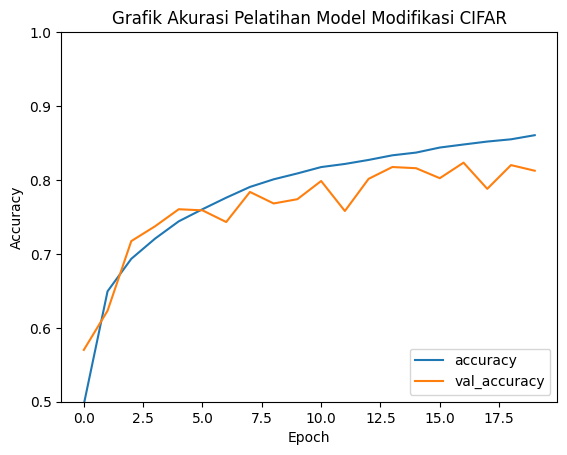

313/313 - 1s - 3ms/step - accuracy: 0.8125 - loss: 0.5774
Akurasi Testing Model Modifikasi: 81.25%


In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# 1. Load dan Normalize Data (Pastikan data di-load ulang agar bersih)
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

# 2. Modifikasi Arsitektur Model CNN
model_mod = models.Sequential()

# Blok Konvolusi 1
model_mod.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.Conv2D(32, (3, 3), padding='same', activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.MaxPooling2D((2, 2)))
model_mod.add(layers.Dropout(0.25)) # Mencegah overfitting

# Blok Konvolusi 2
model_mod.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.Conv2D(64, (3, 3), padding='same', activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.MaxPooling2D((2, 2)))
model_mod.add(layers.Dropout(0.25))

# Blok Fully Connected
model_mod.add(layers.Flatten())
model_mod.add(layers.Dense(128, activation='relu'))
model_mod.add(layers.BatchNormalization())
model_mod.add(layers.Dropout(0.5))
model_mod.add(layers.Dense(10))

# 3. Compile Model
model_mod.compile(optimizer='adam',
                  loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])

# 4. Fit Model (Menggunakan 20 Epoch)
print("Mulai pelatihan model modifikasi")
history_mod = model_mod.fit(train_images, train_labels, epochs=20, validation_data=(test_images, test_labels))


# 5. Visualisasi
plt.plot(history_mod.history['accuracy'], label='accuracy')
plt.plot(history_mod.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1.0])
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Pelatihan Model Modifikasi CIFAR')
plt.show()

# 6. Evaluasi Hasil Akhir
test_loss_mod, test_acc_mod = model_mod.evaluate(test_images, test_labels, verbose=2)
print(f"Akurasi Testing Model Modifikasi: {test_acc_mod * 100:.2f}%")

Peningkatan akurasi hingga 81.25% berhasil dicapai melalui beberapa modifikasi teknis pada arsitektur model CNN. Langkah utamanya mencakup penambahan Batch Normalization untuk menstabilkan aliran data di dalam jaringan, sehingga proses komputasi atau pembelajaran model menjadi lebih cepat dan efisien. Selain itu, teknik Dropout diterapkan untuk mencegah overfitting, yakni masalah di mana model hanya menghafal data latih namun gagal mengenali data pengujian yang baru. Kemampuan pengenalan pola juga ditingkatkan dengan memperdalam layer konvolusi agar model mampu mengekstrak fitur gambar yang lebih detail dan kompleks. Terakhir, jumlah iterasi pelatihan (epoch) dinaikkan dari 10 menjadi 20 putaran, memberikan waktu yang cukup bagi model untuk memperbarui bobotnya dan meminimalkan nilai error secara maksimal.

#### **Pembuatan Model CNN untuk Dataset MNIST**

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Mulai pelatihan model MNIST
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 15s 5ms/step - accuracy: 0.9530 - loss: 0.1503 - val_accuracy: 0.9830 - val_loss: 0.0531
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9858 - loss: 0.0466 - val_accuracy: 0.9903 - val_loss: 0.0326
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9899 - loss: 0.0320 - val_accuracy: 0.9901 - val_loss: 0.0305
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9915 - loss: 0.0257 - val_accuracy: 0.9893 - val_loss: 0.0374
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9933 - loss: 0.0201 - val_accuracy: 0.9895 - val_loss: 0.0347


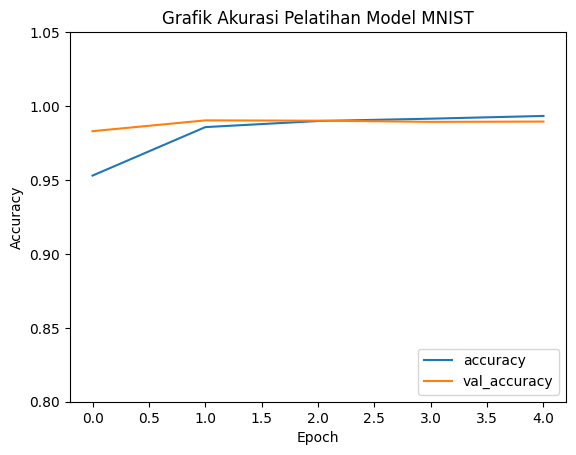

313/313 - 1s - 3ms/step - accuracy: 0.9895 - loss: 0.0347
Akurasi Testing Model MNIST: 98.95%


In [2]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# 1. Load Dataset MNIST
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = datasets.mnist.load_data()

# 2. Pra-pengolahan Data
# Normalisasi pixel menjadi 0-1
mnist_train_images = mnist_train_images / 255.0
mnist_test_images = mnist_test_images / 255.0

# Reshape data untuk menambahkan channel dimensi tunggal (grayscale)
# Dari (60000, 28, 28) menjadi (60000, 28, 28, 1)
mnist_train_images = mnist_train_images.reshape((mnist_train_images.shape[0], 28, 28, 1))
mnist_test_images = mnist_test_images.reshape((mnist_test_images.shape[0], 28, 28, 1))

# 3. Bangun Model CNN untuk MNIST
model_mnist = models.Sequential()

# Layer Konvolusi
model_mnist.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)))
model_mnist.add(layers.MaxPooling2D((2, 2)))
model_mnist.add(layers.Conv2D(64, (3, 3), activation='relu'))
model_mnist.add(layers.MaxPooling2D((2, 2)))
model_mnist.add(layers.Conv2D(64, (3, 3), activation='relu'))

# Layer Fully Connected
model_mnist.add(layers.Flatten())
model_mnist.add(layers.Dense(64, activation='relu'))
model_mnist.add(layers.Dense(10)) # 10 Kelas untuk angka 0-9

# 4. Compile Model
model_mnist.compile(optimizer='adam',
                    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                    metrics=['accuracy'])

# 5. Fit Model
print("Mulai pelatihan model MNIST")
history_mnist = model_mnist.fit(mnist_train_images, mnist_train_labels, epochs=5, validation_data=(mnist_test_images, mnist_test_labels))

# 6. Visualiasai
plt.plot(history_mnist.history['accuracy'], label='accuracy')
plt.plot(history_mnist.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.8, 1.05])
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Pelatihan Model MNIST')
plt.show()

# 7. Evaluasi Akurasi
test_loss_mnist, test_acc_mnist = model_mnist.evaluate(mnist_test_images, mnist_test_labels, verbose=2)
print(f"Akurasi Testing Model MNIST: {test_acc_mnist * 100:.2f}%")

Perbedaan utama antara dataset MNIST dan CIFAR terletak pada karakteristik dimensi warna citra dan tingkat kerumitan pola visualnya. Karena MNIST berisi citra skala keabuan (hitam-putih), data tersebut membutuhkan penyesuaian dimensi matriks awal untuk menambahkan satu saluran warna tunggal, berbeda dengan CIFAR yang secara bawaan sudah memiliki matriks tiga saluran warna (RGB). Selain itu, pola angka pada MNIST jauh lebih sederhana dibandingkan objek nyata pada CIFAR. Karakteristik ini membuat model untuk MNIST dapat dibangun dengan struktur jaringan yang lebih ringkas dan mampu mencapai tingkat akurasi yang sangat tinggi melalui siklus pelatihan yang jauh lebih singkat, tanpa memerlukan teknik stabilisasi tambahan yang rumit.